In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Import necessary libraies 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Read the CSV file using pandas
df = pd.read_csv('insurance.csv')
df

,Id,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01
...,...,...,...,...,...,...,...,...,...,...
1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40
1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07
1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40
1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87


In [5]:
# DataFrame Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1340 non-null   int64  
 1   age            1335 non-null   float64
 2   gender         1340 non-null   object 
 3   bmi            1340 non-null   float64
 4   bloodpressure  1340 non-null   int64  
 5   diabetic       1340 non-null   object 
 6   children       1340 non-null   int64  
 7   smoker         1340 non-null   object 
 8   region         1337 non-null   object 
 9   claim          1340 non-null   float64
dtypes: float64(3), int64(3), object(4)
memory usage: 104.8+ KB


In [6]:
df.shape

(1340, 10)

In [7]:
# Setting floate values with 2 decimal points
pd.set_option("display.float_format","{:.2f}".format)

In [8]:
sns.set(style="whitegrid", palette = "Set2", font_scale = 1.1)

In [9]:
# Find Duplicated Values
df.duplicated().sum()


np.int64(0)

In [10]:
# Find NA Values
df.isna().sum()

Id               0
age              5
gender           0
bmi              0
bloodpressure    0
diabetic         0
children         0
smoker           0
region           3
claim            0
dtype: int64

In [11]:
# Dropping null values from Dataframe
df.dropna(inplace=True)
df.shape

(1332, 10)

In [12]:
# Description of all values the Dataframe
df.describe(include="all")

,Id,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
count,1332.00,1332.00,1332,1332.00,1332.00,1332,1332.00,1332,1332,1332.00
unique,NaN,NaN,2,NaN,NaN,2,NaN,2,4,NaN
top,NaN,NaN,male,NaN,NaN,No,NaN,No,southeast,NaN
freq,NaN,NaN,670,NaN,NaN,695,NaN,1058,442,NaN
mean,674.47,38.09,NaN,30.66,94.19,NaN,1.10,NaN,NaN,13325.25
std,384.70,11.11,NaN,6.12,11.45,NaN,1.21,NaN,NaN,12109.62
min,1.00,18.00,NaN,16.00,80.00,NaN,0.00,NaN,NaN,1121.87
25%,341.75,29.00,NaN,26.20,86.00,NaN,0.00,NaN,NaN,4760.16
50%,674.50,38.00,NaN,30.35,92.00,NaN,1.00,NaN,NaN,9412.97
75%,1007.25,47.00,NaN,34.73,99.00,NaN,2.00,NaN,NaN,16781.33


In [13]:
# Description of numerical values the Dataframe
df.describe()

,Id,age,bmi,bloodpressure,children,claim
count,1332.00,1332.00,1332.00,1332.00,1332.00,1332.00
mean,674.47,38.09,30.66,94.19,1.10,13325.25
std,384.70,11.11,6.12,11.45,1.21,12109.62
min,1.00,18.00,16.00,80.00,0.00,1121.87
25%,341.75,29.00,26.20,86.00,0.00,4760.16
50%,674.50,38.00,30.35,92.00,1.00,9412.97
75%,1007.25,47.00,34.73,99.00,2.00,16781.33
max,1340.00,60.00,53.10,140.00,5.00,63770.43


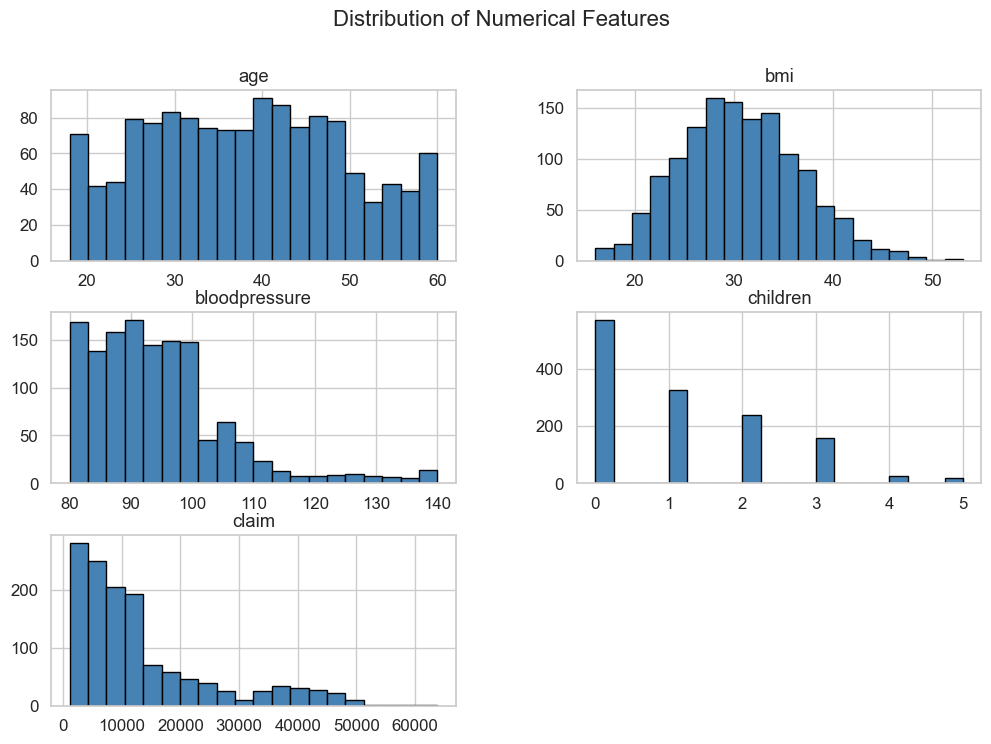

In [14]:
# numerical columns data visualization
numerical_cols = ["age","bmi","bloodpressure","children","claim"]
df[numerical_cols].hist(
    bins = 20, 
    figsize = (12,8), 
    color = 'steelblue', 
    edgecolor = 'black')
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.show()

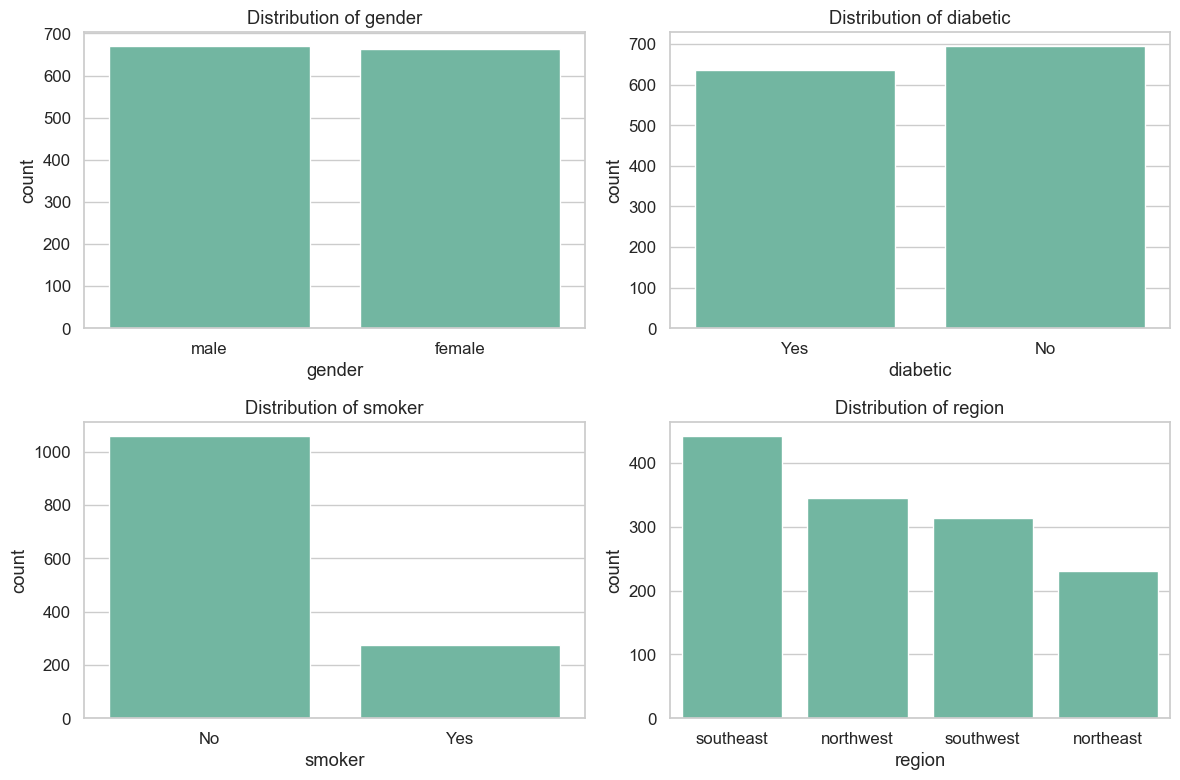

In [15]:
# Catogerical columns data visualization
cat_cols = ["gender","diabetic","smoker","region"]
plt.figure(figsize=(12,8))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(2,2,i)
    sns.countplot(data=df, x = col)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [16]:
# Grouping the healthcare cost using gender and smoker
df.groupby(["gender","smoker"])["claim"].mean().round(2)

gender  smoker
female  No        8762.30
        Yes      30679.00
male    No        8169.25
        Yes      33042.01
Name: claim, dtype: float64

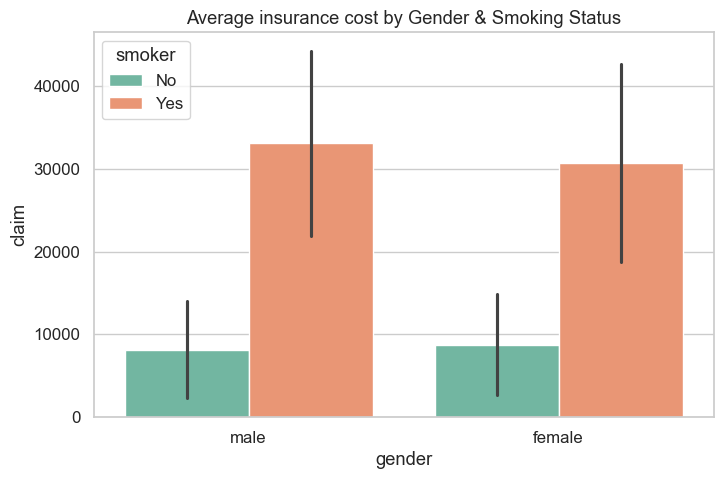

In [17]:
plt.figure(figsize=(8,5))
sns.barplot(
    data = df,
    x = "gender",
    y = "claim",
    hue = "smoker",
    estimator = "mean",
    errorbar="sd")

plt.title("Average insurance cost by Gender & Smoking Status")
plt.show()

In [18]:
pivot_region_diabetic = df.groupby(["region","diabetic"])["claim"].mean().unstack()
pivot_region_diabetic

diabetic,No,Yes
region,,
northeast,16966.86,16818.30
northwest,11442.83,12224.96
southeast,13578.72,12574.09
southwest,13069.91,12313.74


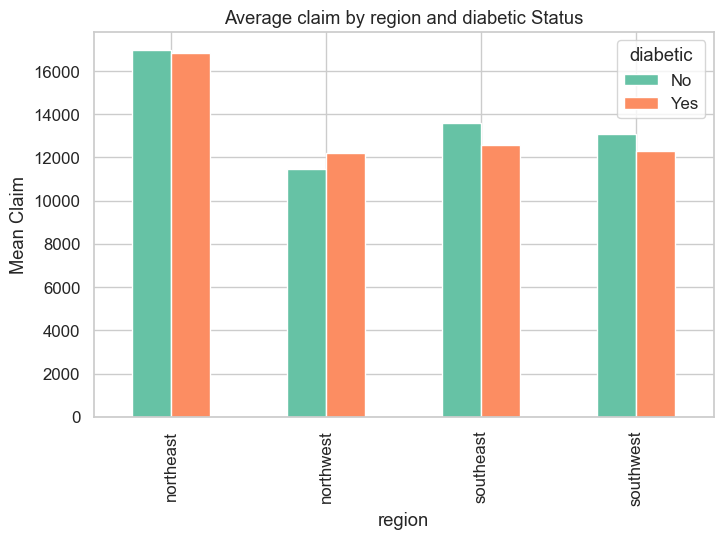

In [19]:
pivot_region_diabetic.plot(kind="bar", figsize = (8,5))
plt.title("Average claim by region and diabetic Status")
plt.ylabel("Mean Claim")
plt.show()

In [20]:
# Pivot Table
pivot_table = pd.pivot_table(
    df,
    values = "claim",
    index = "region",
    columns = "smoker",
    aggfunc = "mean")

pivot_table

smoker,No,Yes
region,,
northeast,11666.11,29673.54
northwest,8076.20,30192.00
southeast,7444.14,34845.00
southwest,8294.75,32269.06


In [21]:
pivot_table = pd.pivot_table(
    df,
    values = "claim",
    index = "children",
    columns = "smoker",
    aggfunc = "mean")

pivot_table

smoker,No,Yes
children,,
0,7698.05,31341.36
1,8303.11,31822.65
2,9493.09,33844.24
3,9614.52,32724.92
4,12121.34,26532.28
5,8183.85,19023.26


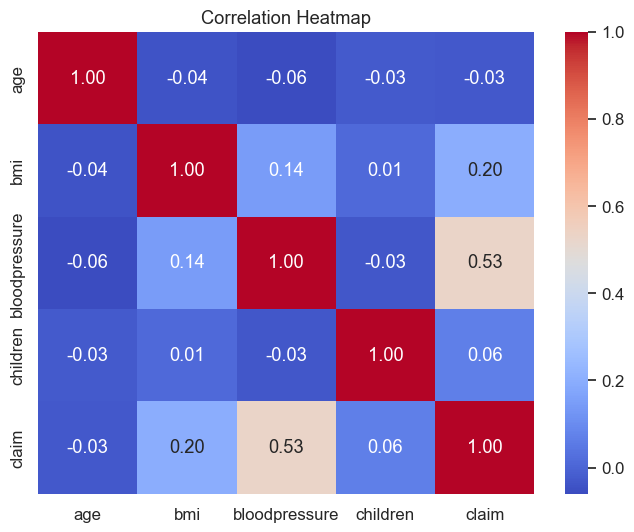

In [22]:
# Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

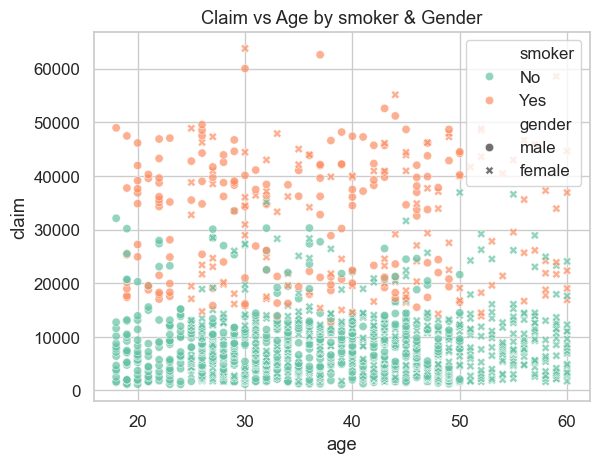

In [23]:
# ScatterPlot
sns.scatterplot(data = df, x = "age", y = "claim", hue = "smoker", style = "gender", alpha = 0.7)
plt.title("Claim vs Age by smoker & Gender")
plt.show()

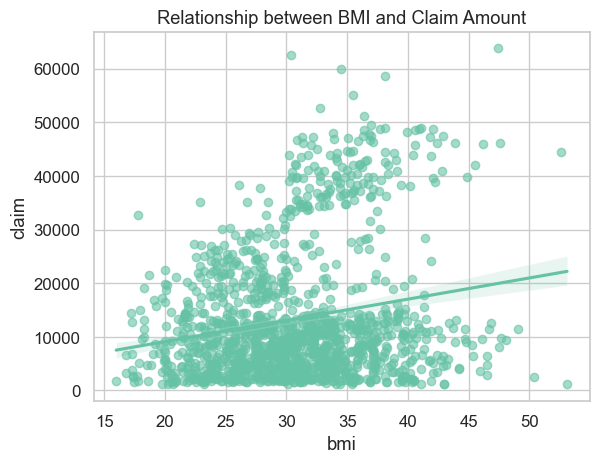

In [24]:
# Regplot
sns.regplot(data=df, x = "bmi", y = "claim", scatter_kws={"alpha":0.6})
plt.title("Relationship between BMI and Claim Amount")
plt.show()

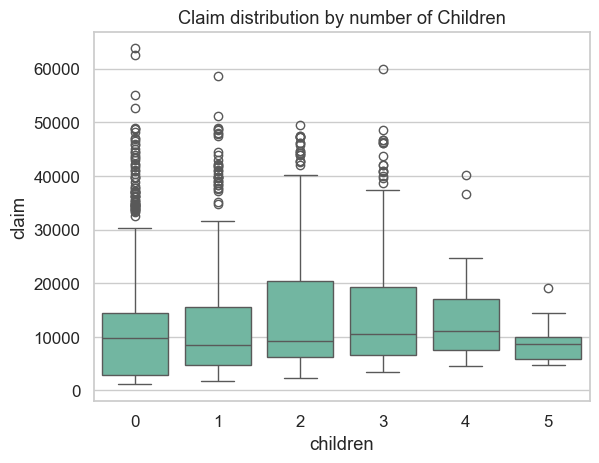

In [25]:
# Box plot
sns.boxplot(data=df, x = "children", y = "claim")
plt.title("Claim distribution by number of Children")
plt.show()

In [26]:
df["age_group"] = pd.cut(df["age"], bins = [0,18,30,45,60,100], labels = ["<18", "18-30","31-45","46-60","60+"])
df

,Id,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim,age_group
0,1,39.00,male,23.20,91,Yes,0,No,southeast,1121.87,31-45
1,2,24.00,male,30.10,87,No,0,No,southeast,1131.51,18-30
7,8,19.00,male,41.10,100,No,0,No,northwest,1146.80,18-30
8,9,20.00,male,43.00,86,No,0,No,northwest,1149.40,18-30
9,10,30.00,male,53.10,97,No,0,No,northwest,1163.46,18-30
...,...,...,...,...,...,...,...,...,...,...,...
1335,1336,44.00,female,35.50,88,Yes,0,Yes,northwest,55135.40,31-45
1336,1337,59.00,female,38.10,120,No,1,Yes,northeast,58571.07,46-60
1337,1338,30.00,male,34.50,91,Yes,3,Yes,northwest,60021.40,18-30
1338,1339,37.00,male,30.40,106,No,0,Yes,southeast,62592.87,31-45


In [27]:
df["age_group"].value_counts()

age_group
31-45    553
46-60    383
18-30    380
<18       16
60+        0
Name: count, dtype: int64

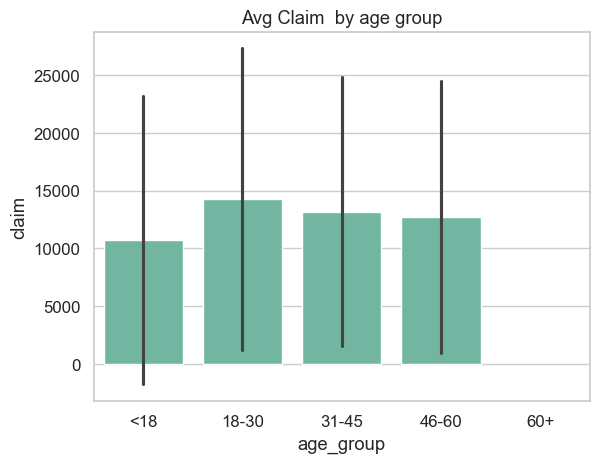

In [28]:
# Bar plot
sns.barplot(data=df, x = "age_group", y = "claim", estimator="mean", errorbar="sd")
plt.title("Avg Claim  by age group")
plt.show()

In [29]:
df["bmi_category"] = pd.cut(df["bmi"], bins = [0,18.5,24.9,29.9,100], labels = ["Underweight","Normal","Overweight","Obese"])
df

,Id,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim,age_group,bmi_category
0,1,39.00,male,23.20,91,Yes,0,No,southeast,1121.87,31-45,Normal
1,2,24.00,male,30.10,87,No,0,No,southeast,1131.51,18-30,Obese
7,8,19.00,male,41.10,100,No,0,No,northwest,1146.80,18-30,Obese
8,9,20.00,male,43.00,86,No,0,No,northwest,1149.40,18-30,Obese
9,10,30.00,male,53.10,97,No,0,No,northwest,1163.46,18-30,Obese
...,...,...,...,...,...,...,...,...,...,...,...,...
1335,1336,44.00,female,35.50,88,Yes,0,Yes,northwest,55135.40,31-45,Obese
1336,1337,59.00,female,38.10,120,No,1,Yes,northeast,58571.07,46-60,Obese
1337,1338,30.00,male,34.50,91,Yes,3,Yes,northwest,60021.40,18-30,Obese
1338,1339,37.00,male,30.40,106,No,0,Yes,southeast,62592.87,31-45,Obese


In [30]:
df["bmi_category"].value_counts()

bmi_category
Obese          702
Overweight     387
Normal         222
Underweight     21
Name: count, dtype: int64

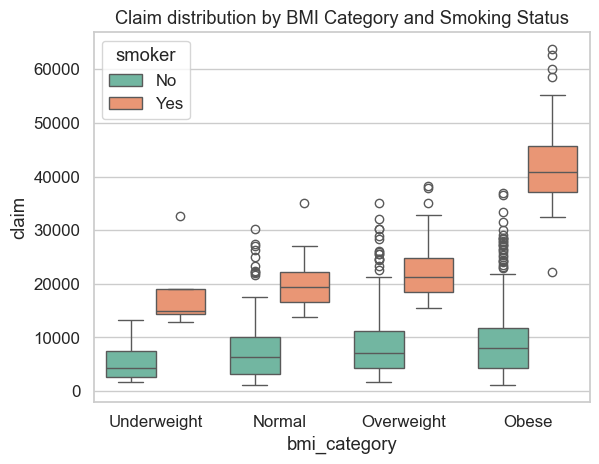

In [31]:
# Box plot
sns.boxplot(data=df, x = "bmi_category", y = "claim", hue = "smoker")
plt.title("Claim distribution by BMI Category and Smoking Status")
plt.show()

In [32]:
# Feature Engineering
region_stats = df.groupby("region").agg(
    smoker_rate = ("smoker", lambda x: (x=="Yes").mean() * 100),
    mean_claim = ("claim","mean")
).reset_index()
region_stats

,region,smoker_rate,mean_claim
0,northeast,29.00,16889.04
1,northwest,16.81,11794.22
2,southeast,20.59,13085.50
3,southwest,18.47,12723.13


In [33]:
df["smoker"].value_counts()

smoker
No     1058
Yes     274
Name: count, dtype: int64

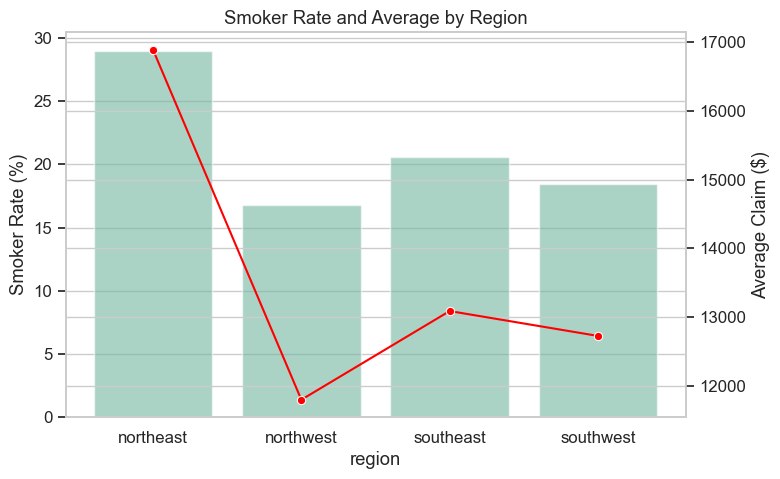

In [34]:
fig, ax1 =  plt.subplots(figsize = (8,5))
sns.barplot(data=region_stats, x="region", y = "smoker_rate", ax=ax1, alpha = 0.6)
ax2 = ax1.twinx()
sns.lineplot(data=region_stats, x = "region", y = "mean_claim", ax = ax2, color = "red", marker= "o")

ax1.set_ylabel("Smoker Rate (%)")
ax2.set_ylabel("Average Claim ($)")
plt.title("Smoker Rate and Average by Region")
plt.show()

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import joblib

In [36]:
df.columns

Index(['Id', 'age', 'gender', 'bmi', 'bloodpressure', 'diabetic', 'children',
       'smoker', 'region', 'claim', 'age_group', 'bmi_category'],
      dtype='object')

In [37]:
X = df[['age', 'gender', 'bmi', 'bloodpressure', 'diabetic', 'children','smoker']]
y = df["claim"]